In [1]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = ["AMD", "DME", "ERM", "NO", "RAO", "RVO", "VID"]
num_classes = len(class_names)

In [9]:
import torch
import torch.nn as nn
from torchvision import models


class CoordAttention(nn.Module):
    def __init__(self, channels, reduction=32):
        super(CoordAttention, self).__init__()

        reduced_channels = max(8, channels // reduction)

        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))

        self.conv1 = nn.Conv2d(channels, reduced_channels, kernel_size=1)
        self.bn1 = nn.BatchNorm2d(reduced_channels)
        self.act = nn.ReLU(inplace=True)

        self.conv_h = nn.Conv2d(reduced_channels, channels, kernel_size=1)
        self.conv_w = nn.Conv2d(reduced_channels, channels, kernel_size=1)

    def forward(self, x):
        identity = x

        n, c, h, w = x.size()

        x_h = self.pool_h(x)
        x_w = self.pool_w(x).permute(0, 1, 3, 2)

        y = torch.cat([x_h, x_w], dim=2)
        y = self.conv1(y)
        y = self.bn1(y)
        y = self.act(y)

        x_h, x_w = torch.split(y, [h, w], dim=2)
        x_w = x_w.permute(0, 1, 3, 2)

        a_h = torch.sigmoid(self.conv_h(x_h))
        a_w = torch.sigmoid(self.conv_w(x_w))

        out = identity * a_h * a_w
        return out


class ConvNeXtWithCoordAttention(nn.Module):
    def __init__(self, num_classes):
        super(ConvNeXtWithCoordAttention, self).__init__()

        self.model = models.convnext_tiny(weights=None)

        in_features = self.model.classifier[2].in_features
        self.model.classifier[2] = nn.Linear(in_features, num_classes)

        self.coord_attention = CoordAttention(768)

    def forward(self, x):
        x = self.model.features(x)
        x = self.coord_attention(x)
        x = self.model.avgpool(x)
        x = self.model.classifier(x)
        return x

In [10]:
# # Convnext_tiny 

# def load_convnext_model(checkpoint_path):
#     model = models.convnext_tiny(weights=None)

#     in_features = model.classifier[2].in_features
#     model.classifier[2] = nn.Linear(in_features, num_classes)

#     checkpoint = torch.load(checkpoint_path, map_location=device)

#     if "model_state_dict" in checkpoint:
#         model.load_state_dict(checkpoint["model_state_dict"])
#     else:
#         model.load_state_dict(checkpoint)

#     model = model.to(device)
#     model.eval()

#     return model

    

In [11]:
# ConvNeXt + CoordAttention

def load_convnext_model(checkpoint_path):
    
    model = ConvNeXtWithCoordAttention(num_classes=num_classes)
    
    checkpoint = torch.load(checkpoint_path, map_location=device)

    if "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    else:
        model.load_state_dict(checkpoint)

    model = model.to(device)
    model.eval()

    return model

In [12]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)
    return image, tensor

In [13]:
def gradcam_severity(image_path, model):
    image, input_tensor = preprocess_image(image_path)

    activations = []
    gradients = []

    # # Convnext_tiny
    # target_layer = model.features[7][-1]
    
    # ConvNeXt + CoordAttention
    target_layer = model.model.features[7][-1]

    def forward_hook(module, input, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    fh = target_layer.register_forward_hook(forward_hook)
    bh = target_layer.register_full_backward_hook(backward_hook)

    output = model(input_tensor)

    probs = torch.softmax(output, dim=1)
    confidence, pred_idx = torch.max(probs, dim=1)

    pred_idx = pred_idx.item()
    confidence = confidence.item()
    predicted_class = class_names[pred_idx]

    model.zero_grad()
    output[0, pred_idx].backward()

    acts = activations[0].detach()
    grads = gradients[0].detach()

    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = (weights * acts).sum(dim=1)
    cam = torch.relu(cam)

    cam = cam.squeeze().cpu().numpy()
    cam = cv2.resize(cam, (224, 224))
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    fh.remove()
    bh.remove()

    # Grad-CAM region analysis
    mask = cam >= 0.5
    activated_ratio = mask.sum() / mask.size

    h, w = cam.shape
    center_mask = np.zeros_like(mask)
    center_mask[int(h*0.3):int(h*0.7), int(w*0.3):int(w*0.7)] = 1

    center_overlap = np.sum(mask * center_mask) / (np.sum(mask) + 1e-8)

    if center_overlap >= 0.5:
        region = "Central retinal region"
    else:
        region = "Peripheral retinal region"

    # Severity scoring
    if predicted_class == "NO":
        disease_score = 0
    elif predicted_class in ["ERM", "VID"]:
        disease_score = 1
    else:
        disease_score = 2

    if confidence >= 0.85:
        confidence_score = 2
    elif confidence >= 0.65:
        confidence_score = 1
    else:
        confidence_score = 0

    if activated_ratio >= 0.25:
        area_score = 2
    elif activated_ratio >= 0.10:
        area_score = 1
    else:
        area_score = 0

    if center_overlap >= 0.5:
        region_score = 1
    else:
        region_score = 0

    total_score = disease_score + confidence_score + area_score + region_score

    if predicted_class == "NO":
        severity = "Low"
    elif total_score >= 6:
        severity = "High"
    elif total_score >= 3:
        severity = "Medium"
    else:
        severity = "Low"

    # Visualization
    img = np.array(image.resize((224, 224))) / 255.0

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

    overlay = 0.5 * img + 0.5 * heatmap
    overlay = np.clip(overlay, 0, 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Original OCT")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap="jet")
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(f"{predicted_class} | {confidence:.2f}\nSeverity: {severity}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Predicted Disease :", predicted_class)
    print("Confidence        :", round(confidence, 4))
    print("Grad-CAM Region   :", region)
    print("Activated Ratio   :", round(activated_ratio, 4))
    print("Total Score       :", total_score)
    print("Severity Level    :", severity)

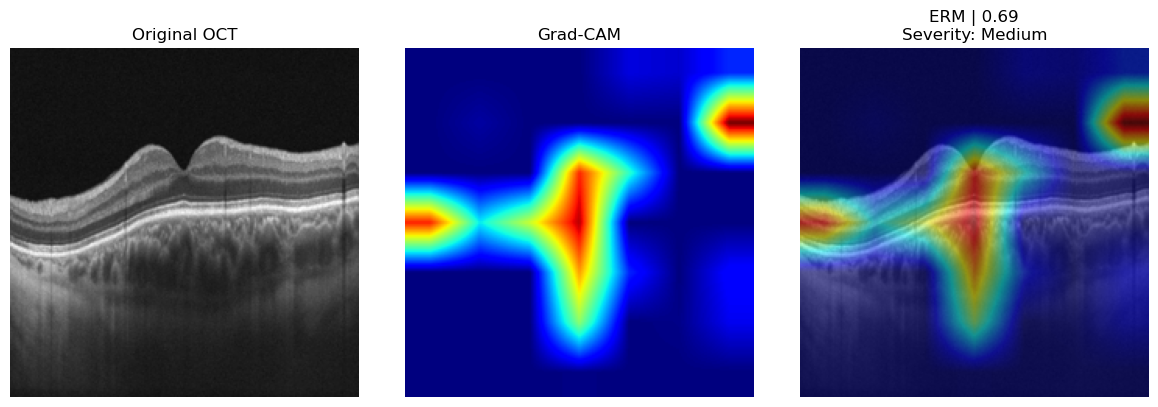

Predicted Disease : ERM
Confidence        : 0.6879
Grad-CAM Region   : Central retinal region
Activated Ratio   : 0.1007
Total Score       : 4
Severity Level    : Medium


In [17]:
checkpoint_path = "coordatt_fold1_5_best.pth"

image_path = r"C:\Users\chris\Documents\Research\dataset\OCTDL\data\NO\norm_e_55.jpg"

model = load_convnext_model(checkpoint_path)

gradcam_severity(image_path, model)